# Task 4 – Teil 4b: Erneuerbare-Energien-Szenarien einzeln und kombiniert

### Aufgabenstellung (Abschnitt 4 des Arbeitsauftrags)

> *Betrachten Sie im folgenden immer die möglichen Schalterstellungen der Schalter S1-S3. Untersuchen Sie mindestens die folgenden Szenarien einzeln und in sinnvollen Kombinationen: 1. Windpark an der Mittelspannung […] 2. Ortsnetz mit fluktuierender Einspeisung und Nutzung: Bilden Sie im neu aufgebauten Ortsnetz zeitlich veränderliche Last und dezentrale Einspeisung ab […]. Dokumentieren Sie Zeitauflösung, Profilherkunft oder transparente synthetische Erzeugung, Skalierung und Vorzeichenkonvention. 3. Großflächen-PV […]*
>
> *Wählen Sie für jedes Szenario plausible hohe und niedrige Einspeise- und Lastsituationen. Vergleichen Sie die Resultate mit der Baseline und halten Sie fest, ob und warum sich die Ergebnisse durch Anschlussort, Dimensionierung, Blindleistungsverhalten oder gleichzeitigen Betrieb unterscheiden.*

| Anforderung | wo |
|---|---|
| Windpark und Großflächen-PV: Anschlussort, Leistung, Profil, Leistungsfaktor | Teil 4a (Anschluss), Datengrundlage 1.2, 1.3, 1.5 |
| Ortsnetz mit Last und dezentraler Einspeisung, Profile, Skalierung, Vorzeichen | Abschnitt 2, Datengrundlage 1.6 |
| Szenarien einzeln und kombiniert, alle Schalterstellungen, Vergleich mit der Baseline | Abschnitt 3 |
| hohe und niedrige Einspeise- und Lastsituationen | Abschnitt 4 |
| Blindleistungsverhalten | Abschnitt 5 |
| Anschlussort, Dimensionierung, Blindleistung, gleichzeitiger Betrieb | Abschnitt 6 |

### Szenarien

| Kurzname | Inhalt | Herkunft |
|---|---|---|
| Baseline | ausgelegtes Netz mit Ortsnetz an Bus 12 und rONT-Regelung, ohne Erzeuger | Teil 3, 3b |
| Wind | Windpark 15 × V90-2.0 MW = 30 MW an Bus 1 | Teil 4a |
| PV | PV-Freiflächenanlage 10 MWp an Bus 12 | Teil 4a |
| Ortsnetz | Haushalte mit PV und Speicher im Wohngebiet, Variante „heute“ | Abschnitt 2 |
| Wind + PV | gewählte Kombination aus Teil 4a | Teil 4a |
| Wind + PV + Ortsnetz | alle drei Szenarien gleichzeitig = Netz am Ende von Teil 4 (Grundlage für Teil 5) | Abschnitt 2 |

In jedem Vergleich bleiben Netz, Lasten, Profile, Wetter (12 typische Wochen, stündlich) und Regelung (drei rONT-Regler) gleich; verändert wird nur, welche Erzeuger angeschlossen sind und wie die Schalter S1–S3 stehen. Der Backup-Plan aus Teil 3b läuft nicht mit, weil er beim Start die Trennschalter öffnet und damit die vorgegebenen Schalterstellungen überschreiben würde.

Voraussetzung: `Task4-4a_Erzeugung_Anschluss.ipynb` wurde ausgeführt.

## Importe

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # Module liegen in task4/src, das Notebook in task4/notebooks

import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import simulation as sim
import szenarien as sz
import lvnetz
import regelung as rg
import bewertung as bw
import plots
import auswertung as aw
from auswertung import PLAN_MARKER, V_MIN, V_MAX, V_PLAN_MIN, V_PLAN_MAX
from elements import Diagram, Generator, Profile
from profiles import Month

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

sim.ONLY_RUN_IF_CHANGED = True

ausgelegt = sim.loadSimulation("w4_t3_ausgelegt")        # Teil 3: ausgelegtes Netz mit Ortsnetz an Bus 12
kombi = sim.loadSimulation(aw.KOMBI)                      # Teil 4a: Wind an Bus 1 + PV an Bus 12
LABEL = {k: sz.label(k, kurz=True) for k in sz.KEYS}

## 2 Szenario Ortsnetz: Haushalte mit PV-Anlage und Speicher

**Modell:** Alle Haushalte behalten ihren Verbrauch mit dem BDEW-Profil H25 [1], [2]. Zusätzlich erhalten die Haushalte mit PV an jedem Haushaltsbus des Wohngebiets einen Erzeuger mit dem PV-Profil aus der Datengrundlage (Abschnitt 1.3, 1.4), die Haushalte mit Speicher zusätzlich einen Batteriespeicher mit Eigenverbrauchsregelung (Datengrundlage 1.6). Die Zahl der Haushalte ergibt sich aus dem Jahresverbrauch der Last und 3000 kWh je Haushalt [32].

| Größe | Festlegung |
|---|---|
| Zeitauflösung | 1 h, 12 typische Wochen (wie alle Zeitreihen) |
| Verbrauch | H25 (dynamisiert), skaliert über die Jahreshöchstleistung der CIGRE-Last [13] |
| PV-Einspeisung | Wetterdaten Open-Meteo [4], [6], Modul Trina Vertex S+ [11], 9 kWp je Haushalt mit PV [34], [37] |
| Speicher | 8,3 kWh und 4,9 kW je Haushalt mit Speicher [33], [34], Wirkungsgrad 0,95 je Richtung [35] |
| Anteile | heute: 15 % der Haushalte mit PV, davon 6,7 % aller Haushalte mit Speicher [23]; Zukunft: 50 % mit PV, 40 % mit Speicher [24] |
| Vorzeichen (pandapower [17]) | Last > 0: Bezug; Erzeuger > 0: Einspeisung; Speicher > 0: Laden, < 0: Entladen; Ortsnetztrafo `p_hv_mw` < 0: Rückspeisung ins MS-Netz |
| Leistungsfaktor | Haushaltslast cos φ = 0,97, PV cos φ = 1 [30] |

In [2]:
ortsnetz, aufteilung = {}, {}
for variante in aw.PV_HAUSHALTE:
    s, aufteilung[variante] = aw.mit_pv_haushalten(ausgelegt, f"w4_t4b_ortsnetz_{variante}", variante)
    s.runSimulation(controllers=aw.lv_regler(s.net))
    ortsnetz[variante] = s
    print(f"Variante {variante}:")
    display(plots.table(aufteilung[variante], decimals=2))

Simulation 'w4_t4b_ortsnetz_heute': unverändert seit dem Lauf vom 2026-11-08T22:13:31 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Variante heute:


,Bus,Jahresverbrauch [MWh],Haushalte,davon nur PV,davon PV + Speicher,PV [kWp],Speicher [kWh],Speicherleistung [kW]
Last,,,,,,,,
LV Load R1,LV Bus R1,838.34,279.45,23.19,18.72,377.25,155.40,91.69
LV Load R11,LV Bus R11,62.88,20.96,1.74,1.40,28.29,11.65,6.88
LV Load R15,LV Bus R15,217.97,72.66,6.03,4.87,98.09,40.40,23.84
LV Load R16,LV Bus R16,230.54,76.85,6.38,5.15,103.74,42.73,25.21
LV Load R17,LV Bus R17,146.71,48.90,4.06,3.28,66.02,27.19,16.04
LV Load R18,LV Bus R18,197.01,65.67,5.45,4.40,88.65,36.52,21.55
Summe,,1693.44,564.48,46.85,37.82,762.05,313.91,185.21


Simulation 'w4_t4b_ortsnetz_Zukunft': unverändert seit dem Lauf vom 2026-11-08T22:14:53 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Variante Zukunft:


,Bus,Jahresverbrauch [MWh],Haushalte,davon nur PV,davon PV + Speicher,PV [kWp],Speicher [kWh],Speicherleistung [kW]
Last,,,,,,,,
LV Load R1,LV Bus R1,838.34,279.45,27.94,111.78,1257.50,927.76,547.38
LV Load R11,LV Bus R11,62.88,20.96,2.10,8.38,94.31,69.58,41.05
LV Load R15,LV Bus R15,217.97,72.66,7.27,29.06,326.95,241.22,142.32
LV Load R16,LV Bus R16,230.54,76.85,7.68,30.74,345.81,255.13,150.53
LV Load R17,LV Bus R17,146.71,48.90,4.89,19.56,220.06,162.36,95.79
LV Load R18,LV Bus R18,197.01,65.67,6.57,26.27,295.51,218.02,128.63
Summe,,1693.44,564.48,56.45,225.79,2540.16,1874.07,1105.70


In [3]:
basis_t3 = ausgelegt.copy("w4_t4b_baseline", overwrite=True)        # Baseline mit derselben Regelung (nur rONT)
basis_t3.runSimulation(controllers=aw.lv_regler(basis_t3.net))
vergleich = {"Baseline": basis_t3, **{f"Ortsnetz {k}": s for k, s in ortsnetz.items()}}

def ortsnetz_kennwerte(s):
    r = s.results
    t = r.trafo_p_mw["LV Trafo R0-R1"]
    pv = r.sgen_p_mw[[c for c in r.sgen_p_mw if c.startswith("LV PV")]].sum(axis=1) if len(r.sgen_p_mw.columns) else 0 * t
    return {"PV-Erzeugung Wohngebiet [MWh]": float(pv.sum()),
            "Bezug Ortsnetztrafo R [MWh]": float(t.clip(lower=0).sum()),
            "Rückspeisung Ortsnetztrafo R [MWh]": float((-t).clip(lower=0).sum()),
            "Stunden Rückspeisung Trafo R": int((t < -0.001).sum()),
            "max. Rückspeisung Trafo R [MW]": float(max(0.0, -t.min())),
            "Auslastung Trafo R max [%]": float(r.trafo_loading["LV Trafo R0-R1"].max()),
            "U max NS [pu]": float(r.vm_pu[[c for c in r.vm_pu if c.startswith("LV Bus")]].max().max()),
            "U min NS [pu]": float(r.vm_pu[[c for c in r.vm_pu if c.startswith("LV Bus")]].min().min()),
            "Stufenschritte rONT R": int(rg.schaltvorgaenge(s).get("Stufenschritte LV Trafo R0-R1", 0)),
            "Stunden Stufe +1/+2 (senken) R": int((r.tap_pos["LV Trafo R0-R1"] > 0).sum()),
            "Stunden Stufe −1/−2 (anheben) R": int((r.tap_pos["LV Trafo R0-R1"] < 0).sum())}

plots.table(pd.DataFrame({k: ortsnetz_kennwerte(s) for k, s in vergleich.items()}), decimals=3)

Simulation 'w4_t4b_baseline': unverändert seit dem Lauf vom 2026-11-08T22:16:07 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


,Baseline,Ortsnetz heute,Ortsnetz Zukunft
PV-Erzeugung Wohngebiet [MWh],0.000,214.418,714.726
Bezug Ortsnetztrafo R [MWh],400.589,264.469,162.906
Rückspeisung Ortsnetztrafo R [MWh],0.000,75.834,424.953
Stunden Rückspeisung Trafo R,0.000,390.000,574.000
max. Rückspeisung Trafo R [MW],0.000,0.450,1.727
Auslastung Trafo R max [%],66.838,75.449,293.251
U max NS [pu],1.027,1.050,1.202
U min NS [pu],0.950,0.950,0.951
Stufenschritte rONT R,92.000,150.000,278.000
Stunden Stufe +1/+2 (senken) R,0.000,131.000,443.000


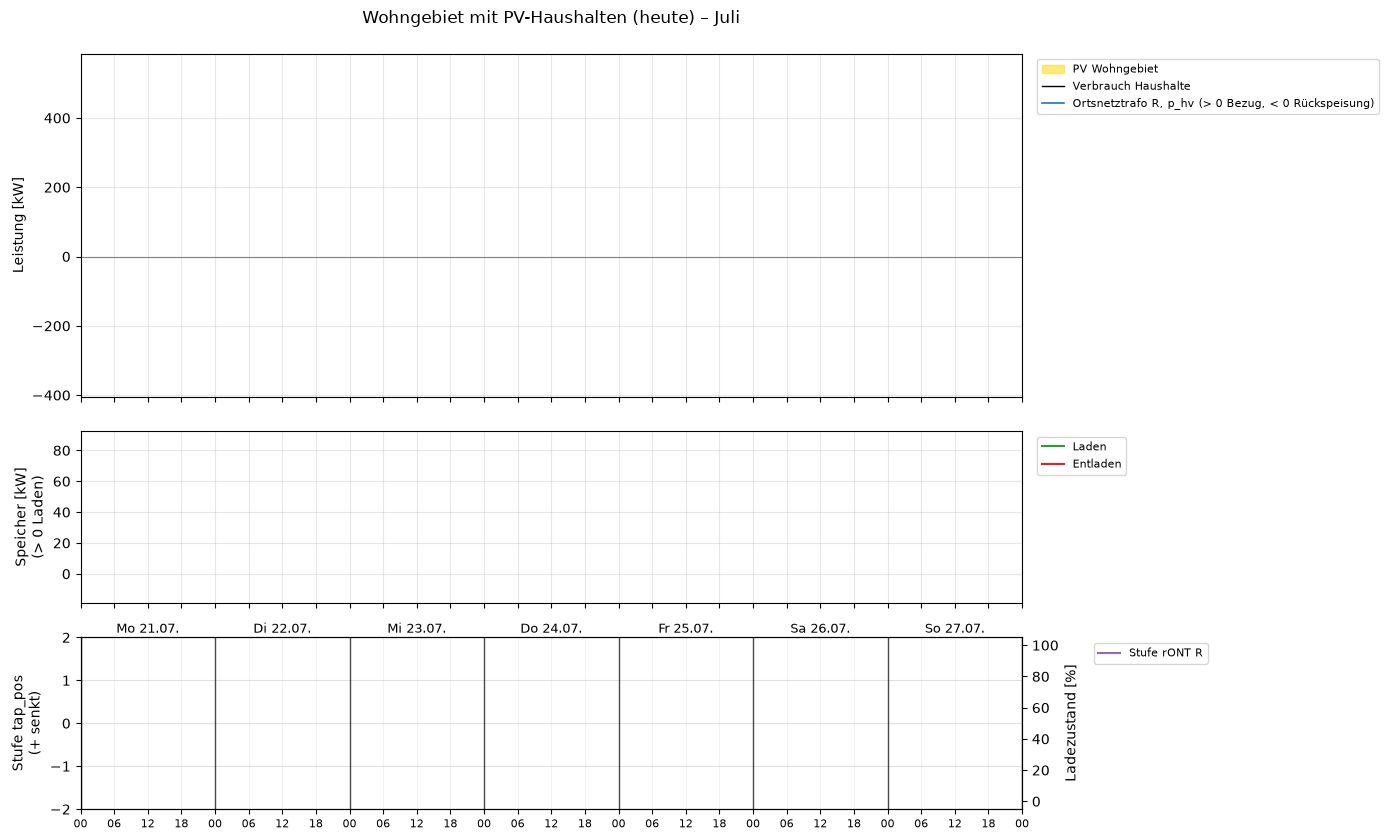

In [4]:
s = ortsnetz["heute"]
r = s.results
idx = r.info.index[r.info["month"] == "JULY"]
pv = r.sgen_p_mw.loc[idx, [c for c in r.sgen_p_mw if c.startswith("LV PV")]].sum(axis=1) * 1000
last = r.load_p_mw.loc[idx, [c for c in r.load_p_mw if c.startswith("LV Load R")]].sum(axis=1) * 1000
speicher = r.storage_p_mw.loc[idx].sum(axis=1) * 1000
trafo = r.trafo_p_mw.loc[idx, "LV Trafo R0-R1"] * 1000
soc = (r.storage_soc_percent.loc[idx] * s.net.storage.set_index("name")["max_e_mwh"]).sum(axis=1) / s.net.storage["max_e_mwh"].sum()
fig, axes = plt.subplots(3, 1, figsize=(14, 8.5), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
x = np.arange(len(idx))
axes[0].fill_between(x, pv, color="gold", alpha=0.5, label="PV Wohngebiet")
axes[0].plot(x, last, color="black", lw=1, label="Verbrauch Haushalte")
axes[0].plot(x, trafo, color="tab:blue", lw=1.2, label="Ortsnetztrafo R, p_hv (> 0 Bezug, < 0 Rückspeisung)")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].set_ylabel("Leistung [kW]")
axes[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].set_title("Wohngebiet mit PV-Haushalten (heute) – Juli", pad=22)
axes[1].bar(x, speicher, color=np.where(speicher >= 0, "tab:green", "tab:red"), width=1.0)
axes[1].set_ylabel("Speicher [kW]\n(> 0 Laden)")
axes[1].plot([], [], color="tab:green", label="Laden"); axes[1].plot([], [], color="tab:red", label="Entladen")
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[2].step(x, r.tap_pos.loc[idx, "LV Trafo R0-R1"], where="post", color="tab:purple", label="Stufe rONT R")
axes[2].set_ylabel("Stufe tap_pos\n(+ senkt)")
axes[2].set_yticks(range(-2, 3))
ax2 = axes[2].twinx()
ax2.plot(x, soc, color="tab:green", lw=0.8, ls="--", label="Ladezustand (Mittel)")
ax2.set_ylabel("Ladezustand [%]")
axes[2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.07, 1))
for ax in axes:
    ax.grid(alpha=0.3)
plots.week_axis(axes[2], idx)
plt.tight_layout()
plt.show()

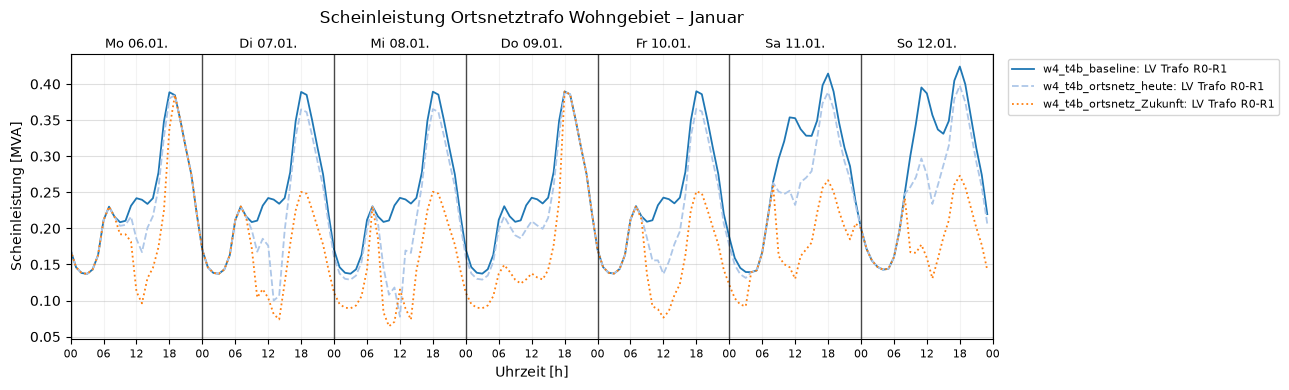

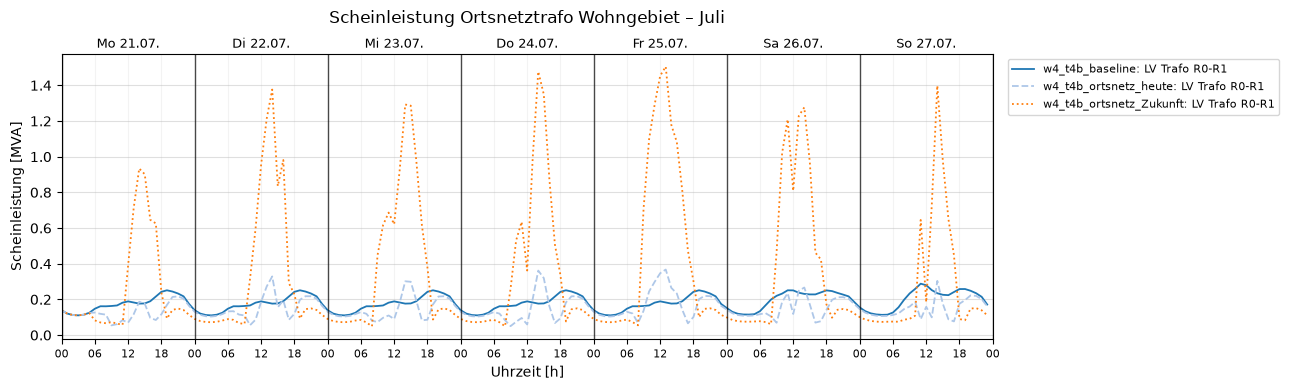

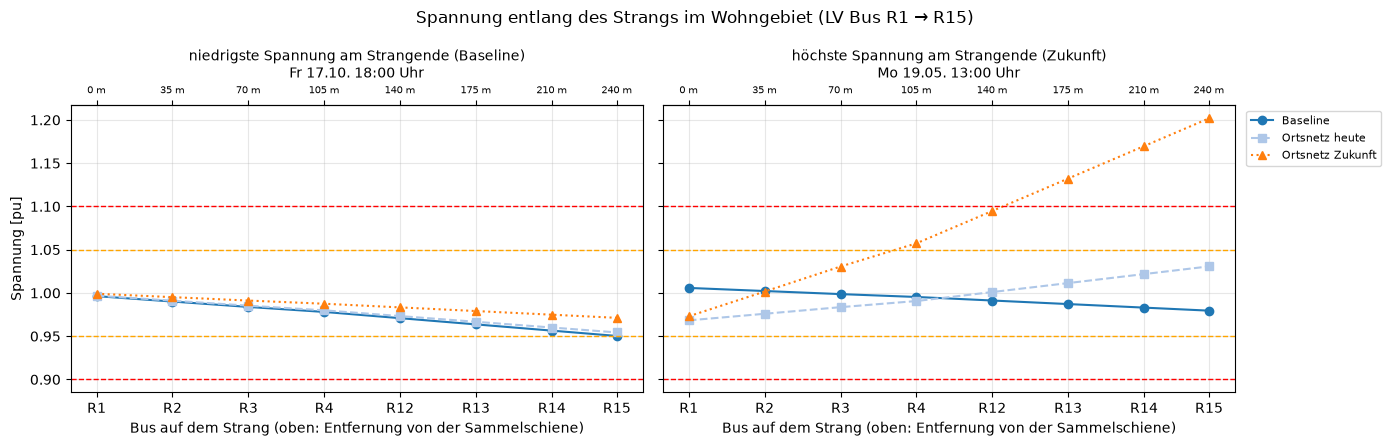

In [5]:
sim.compare(list(vergleich.values()), Diagram.APPARENT_POWER, ["LV Trafo R0-R1"], months=[Month.JANUARY, Month.JULY],
            title="Scheinleistung Ortsnetztrafo Wohngebiet")
ref = basis_t3.results.vm_pu["LV Bus R15"]
pv_max = ortsnetz["Zukunft"].results.vm_pu["LV Bus R15"].idxmax()
aw.spannungsprofil(vergleich, "LV Bus R1", "LV Bus R15",
                   {"niedrigste Spannung am Strangende (Baseline)": ref.idxmin(),
                    "höchste Spannung am Strangende (Zukunft)": pv_max},
                   titel="Spannung entlang des Strangs im Wohngebiet (LV Bus R1 → R15)")

**Befund Ortsnetz (Wohngebiet, rONT-Regelung aktiv, S1–S3 offen):**

- **Heute** (15 % der 564 Haushalte mit zusammen 762 kWp PV, davon 38 Haushalte mit zusammen 314 kWh Speicher): Die PV-Anlagen erzeugen in den 12 Wochen 214 MWh, der Bezug über Ortsnetztrafo R sinkt von 401 auf 264 MWh. In **390 Stunden** fließt Leistung ins MS-Netz zurück, zusammen 76 MWh, höchstens **0,45 MW**. Der Lastfluss kehrt sich also an sonnigen Mittagen tatsächlich um. Das konnten die Bezugsprofile P25/S25 vorher nicht abbilden.
- **Wirkung auf die Spannung:** Die höchste NS-Spannung steigt von 1,027 auf 1,050 pu, also genau an die obere Grenze des Planungsbands. Der rONT regelt in 131 Stunden nach unten (Stufe +1 oder +2) und hält die Spannung damit im Band; die Zahl der Stufenschritte steigt von 92 auf 150. Ortsnetztrafo R ist mit höchstens 75 % ausgelastet, die niedrigste Spannung (0,950 pu zur Abendspitze) ändert sich nicht, weil die PV dann nichts erzeugt.
- **Zukunft** (50 % der Haushalte mit PV, 40 % mit Speicher, 2,5 MWp): Die Rückspeisung erreicht **1,73 MW** in 574 Stunden. Ortsnetztrafo R (0,63 MVA) ist in 328 Stunden überlastet, bis 293 %; das erste Kabel (Line R1-R2) bis 287 %. Selbst mit der höchsten Stufe +2 steigt die Spannung am Strangende R15 auf **1,20 pu**, in 220 Stunden über die Arbeitsgrenze 1,10 pu. Die Stufen ±2 × 2,5 % reichen nicht aus.
- **Erklärung:** Die Spannungsanhebung am Strangende folgt ΔU ≈ (R·P + X·Q)/U mit negativem P (Rückspeisung). In den Kabeln des Wohngebiets ist R groß gegenüber X, deshalb wirkt vor allem die Wirkleistung. Die Speicher helfen nur am Vormittag: Sie laden mit dem ersten Überschuss und sind zur Mittagsspitze voll (Datengrundlage, Abschnitt 1.6).
- **Einordnung:** Im CIGRE-Netz hängen an Ortsnetztrafo R alle 564 Haushalte des Wohngebiets (Load R1 bündelt weitere Stränge). Für die Variante Zukunft wären ein größerer Trafo, verstärkte Kabel oder eine Begrenzung der Einspeisung nötig, z. B. eine netzdienliche Steuerung der Speicher (Teil 9). Weiter verwendet wird die Variante **heute**, die das Netz mit Regelung zulässig betreiben kann.

## 3 Szenarien einzeln und kombiniert in allen Schalterstellungen

Jedes Szenario wird in allen acht Schaltzuständen über 12 Wochen gerechnet (rONT-Regelung aktiv). Die Baseline sind die Zeitreihen aller Schalterstellungen mit rONT-Regelung aus Teil 3b (`w4_t3r_…`). Das Szenario „Wind + PV + Ortsnetz“ ist das Netz am Ende von Teil 4; seine Zeitreihen werden in Teil 5 weiter ausgewertet.

In [6]:
def mit_erzeugern(name, erzeuger):
    s = ausgelegt.copy(name, overwrite=True)
    for e in erzeuger:
        s.createElement(e)
    s.save(results=False)
    return s

WIND = Generator("Windpark", bus="Bus 1", profile=Profile.WIND, p_mw=30.0)
PV = Generator("PV-Freifläche", bus="Bus 12", profile=Profile.PV, kwp=10_000)
basen = {
    "Wind": mit_erzeugern("w4_t4b_wind", [WIND]),
    "PV": mit_erzeugern("w4_t4b_pv", [PV]),
    "Ortsnetz": aw.mit_pv_haushalten(ausgelegt, "w4_t4b_on", "heute")[0],
    "Wind + PV": mit_erzeugern("w4_t4b_wp", [WIND, PV]),
}
ende_t4, _ = aw.netz_ende_teil4()                           # Wind + PV + Ortsnetz (gleiches Netz wie in Teil 5)

szen = {"Baseline": {k: sim.loadSimulation(f"w4_t3r_{k}") for k in sz.KEYS}}
prefix = {"Wind": "w4_t4b_wind", "PV": "w4_t4b_pv", "Ortsnetz": "w4_t4b_on", "Wind + PV": "w4_t4b_wp"}
for name, b in basen.items():
    szen[name] = sz.zeitreihe_alle(b, prefix=prefix[name], controllers=aw.lv_regler(b.net))
szen["Wind + PV + Ortsnetz"] = sz.zeitreihe_alle(ende_t4, prefix="w4_t5", controllers=aw.lv_regler(ende_t4.net))
print({k: len(v) for k, v in szen.items()})

Simulation 'w4_t4b_wind_000': unverändert seit dem Lauf vom 2026-11-08T22:18:29 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_001': unverändert seit dem Lauf vom 2026-11-08T22:19:54 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_010': unverändert seit dem Lauf vom 2026-11-08T22:21:09 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_011': unverändert seit dem Lauf vom 2026-11-08T22:22:18 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_100': unverändert seit dem Lauf vom 2026-11-08T22:23:28 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_101': unverändert seit dem Lauf vom 2026-11-08T22:24:42 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_wind_110': unverändert seit dem Lauf vom 2026-11-08

In [7]:
KENN = ["U min MS [pu]", "U max MS [pu]", "U min NS [pu]", "U max NS [pu]", "Leitung max MS [%]", "Leitung max NS [%]",
        "Trafo max HS/MS [%]", "Ortsnetztrafo max [%]", "Stunden Rückspeisung 110 kV", "max. Rückspeisung 110 kV [MW]",
        "Verluste [MWh]"]
werte = {}
for name, sims in szen.items():
    w, _ = bw.kennwerte({LABEL[k]: s for k, s in sims.items()})
    werte[name] = w
gesamt = pd.concat(werte, names=["Szenario", "Schaltzustand"])
gesamt["Stunden außerhalb der Arbeitsgrenzen"] = gesamt[list(bw.KRITERIEN.values())].sum(axis=1)
gesamt["Stunden Planungsband verletzt"] = gesamt[["Stunden U < 0,95 MS", "Stunden U < 0,95 NS"] +
                                                 [c for c in ("Stunden U > 1,05 MS", "Stunden U > 1,05 NS") if c in gesamt]].sum(axis=1)
print("Normalschaltzustand (alle offen), alle Szenarien:")
display(plots.table(gesamt.xs(LABEL["000"], level=1)[KENN + ["Stunden außerhalb der Arbeitsgrenzen", "Stunden Planungsband verletzt"]].astype(float).T, decimals=3))

Normalschaltzustand (alle offen), alle Szenarien:


Szenario,Baseline,Wind,PV,Ortsnetz,Wind + PV,Wind + PV + Ortsnetz
U min MS [pu],0.949,0.951,0.949,0.949,0.951,0.951
U max MS [pu],1.024,1.025,1.024,1.024,1.025,1.025
U min NS [pu],0.950,0.950,0.950,0.950,0.950,0.950
U max NS [pu],1.027,1.027,1.027,1.050,1.027,1.050
Leitung max MS [%],78.638,78.491,78.638,78.638,78.491,78.491
Leitung max NS [%],71.073,71.073,71.073,78.615,71.073,78.498
Trafo max HS/MS [%],82.694,88.512,82.694,82.694,88.512,88.512
Ortsnetztrafo max [%],66.838,66.838,66.838,75.449,66.838,75.331
Stunden Rückspeisung 110 kV,0.000,233.000,0.000,0.000,263.000,266.000
max. Rückspeisung 110 kV [MW],0.000,16.100,0.000,0.000,16.100,16.108


**Alle Szenarien und Schaltzustände** – je Kennwert eine Tabelle (Zeilen: Szenarien, Spalten: Schaltzustände):

In [8]:
for k, (cmap, lo, hi) in {"U min MS [pu]": ("RdYlGn", 0.93, 0.98), "U max MS [pu]": ("RdYlGn_r", 1.02, 1.06),
                          "U max NS [pu]": ("RdYlGn_r", 1.02, 1.06), "Leitung max MS [%]": ("YlOrRd", 40, 100),
                          "Trafo max HS/MS [%]": ("YlOrRd", 40, 100), "Stunden Rückspeisung 110 kV": ("Greens", 0, 300),
                          "Verluste [MWh]": ("YlOrRd", 100, 250), "Stunden Planungsband verletzt": ("Reds", 0, 50)}.items():
    print(k)
    tab = gesamt[k].unstack().reindex(index=list(szen), columns=[LABEL[s] for s in sz.KEYS]).astype(float)
    display(plots.table(tab, decimals=3 if "pu" in k else 1, cmap=cmap, vmin=lo, vmax=hi))

U min MS [pu]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
Wind,0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976
PV,0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
Ortsnetz,0.949,0.950,0.949,0.951,0.973,0.973,0.974,0.975
Wind + PV,0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976
Wind + PV + Ortsnetz,0.951,0.952,0.951,0.953,0.974,0.974,0.976,0.976


U max MS [pu]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Wind,1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030
PV,1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Ortsnetz,1.024,1.024,1.024,1.024,1.024,1.024,1.024,1.024
Wind + PV,1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030
Wind + PV + Ortsnetz,1.025,1.025,1.025,1.025,1.030,1.030,1.030,1.030


U max NS [pu]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,1.027,1.027,1.027,1.027,1.039,1.039,1.039,1.039
Wind,1.027,1.027,1.027,1.027,1.041,1.041,1.041,1.041
PV,1.027,1.027,1.027,1.027,1.039,1.039,1.039,1.039
Ortsnetz,1.050,1.050,1.050,1.050,1.050,1.050,1.050,1.050
Wind + PV,1.027,1.027,1.027,1.027,1.041,1.041,1.041,1.041
Wind + PV + Ortsnetz,1.050,1.050,1.050,1.050,1.050,1.050,1.050,1.050


... (6 outputs left out)

Verluste [MWh]


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,162.8,161.0,162.7,160.7,128.6,128.5,128.2,127.7
Wind,154.9,153.1,154.8,152.8,190.1,191.6,190.7,191.1
PV,159.5,157.8,159.5,157.5,132.3,132.4,131.9,131.6
Ortsnetz,161.3,159.5,161.2,159.2,127.4,127.3,126.9,126.4
Wind + PV,151.6,149.8,151.5,149.6,184.4,185.8,184.9,185.3
Wind + PV + Ortsnetz,150.2,148.5,150.2,148.2,183.1,184.5,183.6,184.0


Stunden Planungsband verletzt


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Baseline,8.0,3.0,9.0,0.0,0.0,0.0,0.0,0.0
Wind,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
PV,8.0,3.0,9.0,0.0,0.0,0.0,0.0,0.0
Ortsnetz,8.0,3.0,9.0,0.0,0.0,0.0,0.0,0.0
Wind + PV,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Wind + PV + Ortsnetz,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Änderung gegenüber der Baseline** im jeweils gleichen Schaltzustand:

In [9]:
delta = {}
for name in szen:
    if name == "Baseline":
        continue
    d = gesamt.loc[name, KENN].astype(float) - gesamt.loc["Baseline", KENN].astype(float)
    delta[name] = d.loc[LABEL["000"]]
print("Normalschaltzustand: Szenario − Baseline")
display(plots.table(pd.DataFrame(delta), decimals=3, cmap="RdBu_r", vmin=-30, vmax=30))
for k in ("U max MS [pu]", "Trafo max HS/MS [%]", "Verluste [MWh]"):
    tab = (gesamt[k].unstack() - gesamt.loc["Baseline", k]).drop(index="Baseline").reindex(columns=[LABEL[s] for s in sz.KEYS])
    print(f"{k}: Szenario − Baseline je Schaltzustand")
    display(plots.table(tab.astype(float), decimals=3, cmap="RdBu_r", vmin=-abs(tab.values).max(), vmax=abs(tab.values).max()))

Normalschaltzustand: Szenario − Baseline


,Wind,PV,Ortsnetz,Wind + PV,Wind + PV + Ortsnetz
U min MS [pu],0.002,0.000,0.000,0.002,0.002
U max MS [pu],0.001,0.000,0.000,0.001,0.001
U min NS [pu],-0.000,0.000,-0.000,0.000,-0.000
U max NS [pu],0.000,0.000,0.023,0.000,0.023
Leitung max MS [%],-0.147,0.000,-0.000,-0.147,-0.147
Leitung max NS [%],-0.000,0.000,7.542,0.000,7.425
Trafo max HS/MS [%],5.819,0.000,-0.000,5.819,5.819
Ortsnetztrafo max [%],-0.000,0.000,8.611,-0.000,8.493
Stunden Rückspeisung 110 kV,233.000,0.000,0.000,263.000,266.000
max. Rückspeisung 110 kV [MW],16.100,0.000,0.000,16.100,16.108


U max MS [pu]: Szenario − Baseline je Schaltzustand


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Wind,0.001,0.001,0.001,0.001,0.006,0.006,0.006,0.006
PV,0.000,-0.000,0.000,0.000,0.000,-0.000,-0.000,0.000
Ortsnetz,0.000,-0.000,0.000,-0.000,0.000,0.000,-0.000,-0.000
Wind + PV,0.001,0.001,0.001,0.001,0.006,0.006,0.006,0.006
Wind + PV + Ortsnetz,0.001,0.001,0.001,0.001,0.006,0.006,0.006,0.006


Trafo max HS/MS [%]: Szenario − Baseline je Schaltzustand


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Wind,5.819,5.831,5.819,5.835,0.780,0.498,0.522,0.398
PV,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Ortsnetz,-0.000,0.000,0.000,-0.000,-0.048,-0.048,-0.048,-0.048
Wind + PV,5.819,5.831,5.819,5.835,0.780,0.498,0.522,0.398
Wind + PV + Ortsnetz,5.819,5.831,5.819,5.835,0.780,0.498,0.522,0.398


Verluste [MWh]: Szenario − Baseline je Schaltzustand


Schaltzustand,alle offen,S3 zu,S2 zu,S2+S3 zu,S1 zu,S1+S3 zu,S1+S2 zu,S1+S2+S3 zu
Szenario,,,,,,,,
Wind,-7.913,-7.903,-7.912,-7.902,61.491,63.078,62.569,63.437
PV,-3.282,-3.282,-3.282,-3.282,3.663,3.844,3.769,3.872
Ortsnetz,-1.505,-1.505,-1.505,-1.505,-1.256,-1.248,-1.252,-1.248
Wind + PV,-11.195,-11.185,-11.194,-11.184,55.726,57.266,56.763,57.609
Wind + PV + Ortsnetz,-12.573,-12.564,-12.573,-12.563,54.441,55.986,55.481,56.329


**Befund Szenarien in allen Schalterstellungen (rONT-Regelung aktiv):**

- **Konvergenz:** Alle 6 Szenarien × 8 Schaltzustände × 2016 Stunden konvergieren.
- **Arbeitsgrenzen:** In keinem Szenario und keinem Schaltzustand wird 0,90 … 1,10 pu verletzt oder ein Betriebsmittel über 100 % belastet. Das Planungsband wird nur in Baseline, PV und Ortsnetz in 3 bis 9 Stunden unterschritten (Bus 11 am Ende von Abgang 1 zur Abendspitze, U min 0,949 pu). Der Windpark hebt die MS-Spannung so weit an, dass diese Stunden verschwinden.
- **Windpark (Bus 1):** Er bestimmt das Netz. Bei offenem S1 fließt seine Einspeisung über Trafo 0-1 ins 110-kV-Netz (233 Stunden Rückspeisung, bis 16,1 MW). Trafo 0-1 ist dann mit 88,5 % höher ausgelastet als bei Höchstlast ohne Windpark (82,7 %). Die Leitungen in Abgang 1 entlastet er dagegen leicht. **Mit geschlossenem S1** teilt sich die Einspeisung auf beide Trafos auf: Ein Teil fließt durch Abgang 1 und über Line 14-8 zum Trafo 0-12. Die höchste MS-Leitungsauslastung steigt dann von 42 % (Baseline mit S1) auf **98 bis 99,6 %**, und die Verluste steigen um 61 bis 63 MWh. Mit Windpark sollte S1 im Normalbetrieb offen bleiben.
- **PV-Anlage (Bus 12):** Mit höchstens 8,4 MW speist sie nie mehr ein, als das ganze Netz gleichzeitig verbraucht; deshalb gibt es keine Rückspeisung ins 110-kV-Netz; selbst Trafo 0-12 bezieht immer mindestens 2,6 MW, und Spannungen und Auslastungen ändern sich kaum. Die Verluste sinken bei offenem S1 um 3,3 MWh, mit S1 steigen sie um 3,7 MWh, weil Leistung durch die Masche fließt.
- **Ortsnetz:** Es wirkt nur im Wohngebiet (U max NS 1,050 pu, Ortsnetztrafo 75 %) und ist im MS-Netz kaum zu sehen. Mit S1 bleibt die höchste NS-Spannung bei 1,050 pu, weil der rONT nachregelt.
- **Kombination:** Die Wirkungen addieren sich fast genau. Wind + PV + Ortsnetz hat 266 Stunden Rückspeisung ins 110-kV-Netz (Wind allein 233) und die geringsten Verluste bei offenem S1 (150 MWh, −12,6 MWh gegenüber der Baseline). Die Schalter S2 und S3 ändern wie in den vorigen Teilen fast nichts.

## 4 Hohe und niedrige Einspeise- und Lastsituationen

Aus den Zeitreihen im Normalschaltzustand werden je Szenario typische Extremsituationen herausgegriffen:

| Situation | Auswahl |
|---|---|
| Höchstlast | Stunde mit der größten Summe aller Lasten (in allen Szenarien derselbe Zeitpunkt) |
| hohe Einspeisung, niedrige Last | Stunde mit dem größten Verhältnis Erzeugung/Last (nur Szenarien mit Erzeugern) |
| höchste Einspeisung | Stunde mit der größten Summe aller Erzeuger des Szenarios |
| Schwachlast ohne Einspeisung | Stunde mit der kleinsten Last bei Einspeisung unter 5 % der installierten Leistung |

Für jede Situation werden die Spannungen an **allen** MS- und NS-Bussen sowie die Auslastungen ausgewertet.

In [10]:
def situationen(s):
    r = s.results
    p = r.ext_grid_p_mw.squeeze()
    erz = r.sgen_p_mw.sum(axis=1) if len(r.sgen_p_mw.columns) else pd.Series(0.0, index=p.index)
    last = r.load_p_mw.sum(axis=1)
    out = {"Höchstlast": last.idxmax()}                   # höchste Last (bei allen Szenarien derselbe Zeitpunkt)
    if erz.max() > 0:
        out["hohe Einspeisung, niedrige Last"] = (erz / last).idxmax()   # größtes Verhältnis Erzeugung/Last
        out["höchste Einspeisung"] = erz.idxmax()
        ruhig = erz < 0.05 * erz.max()
        out["Schwachlast ohne Einspeisung"] = last[ruhig].idxmin()
    else:
        out["Schwachlast ohne Einspeisung"] = last.idxmin()
    return out

zeilen, spannungen = {}, {}
for name, sims in szen.items():
    s = sims["000"]
    r = s.results
    for sit, h in situationen(s).items():
        vm = r.vm_pu.loc[h]
        ms, ns = vm[aw.MS_BUSSE], vm[[c for c in vm.index if c.startswith("LV Bus")]]
        zeilen[(name, sit)] = {"Zeitpunkt": f"{h:%d.%m. %H:%M}", "Last [MW]": r.load_p_mw.loc[h].sum(),
                               "Erzeugung [MW]": r.sgen_p_mw.loc[h].sum() if len(r.sgen_p_mw.columns) else 0.0,
                               "Austausch 110 kV [MW]": r.ext_grid_p_mw.squeeze()[h],
                               "U min MS [pu]": ms.min(), "U max MS [pu]": ms.max(), "U min NS [pu]": ns.min(), "U max NS [pu]": ns.max(),
                               "Leitung max [%]": r.line_loading.loc[h].max(), "Trafo max [%]": r.trafo_loading.loc[h].max()}
        spannungen[(name, sit)] = vm
sit_tab = pd.DataFrame(zeilen).T
display(plots.table(sit_tab, decimals=3))

**Spannungen an allen Bussen** in diesen Situationen (Zeilen: Busse; Spalten: Szenario und Situation):

In [11]:
u_alle = pd.DataFrame(spannungen)
u_alle = u_alle.loc[[b for b in u_alle.index if b != "Bus 0"]]
plots.table(u_alle, decimals=3, cmap="RdYlGn_r", vmin=0.94, vmax=1.06)

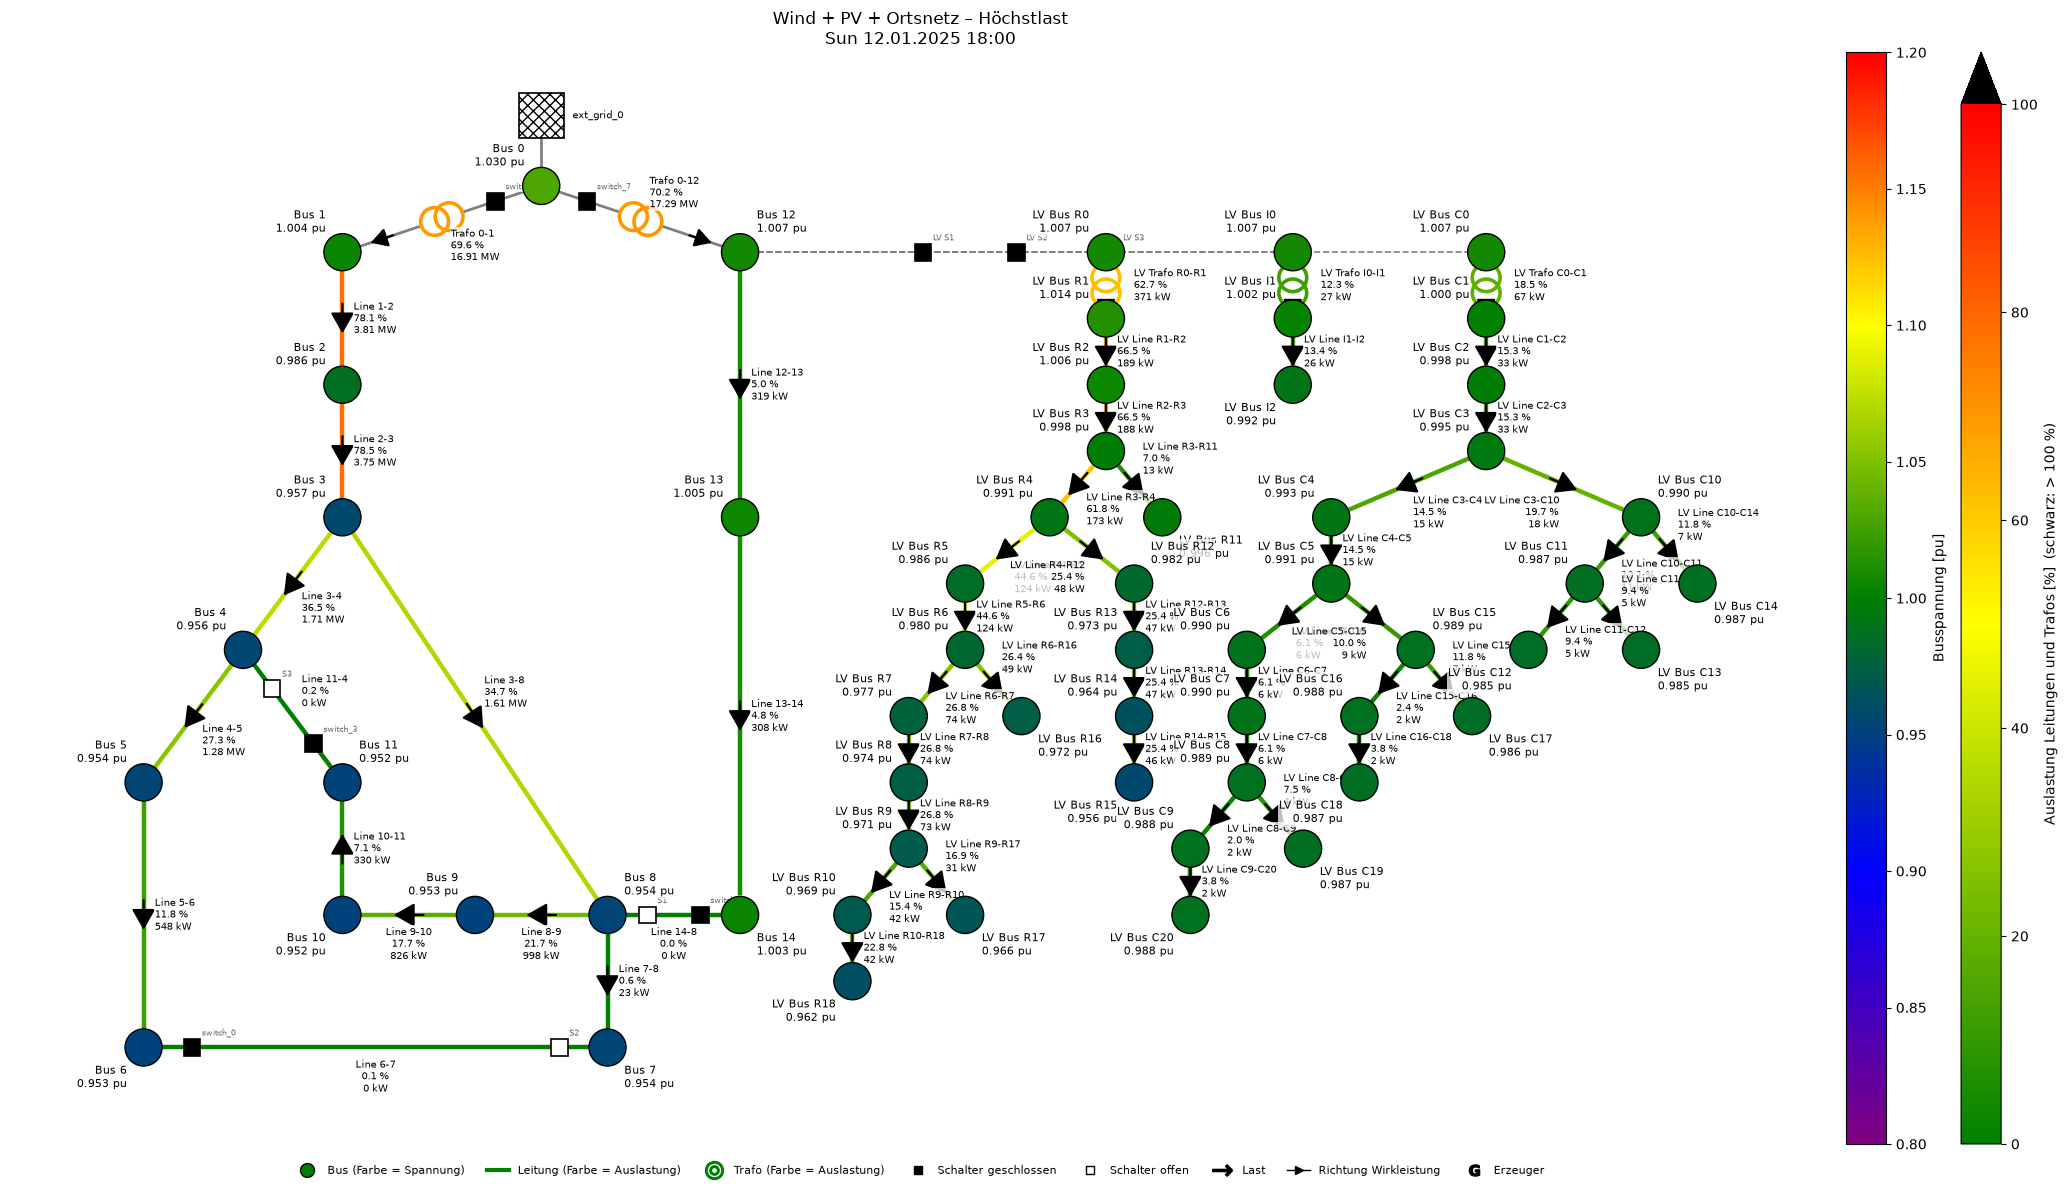

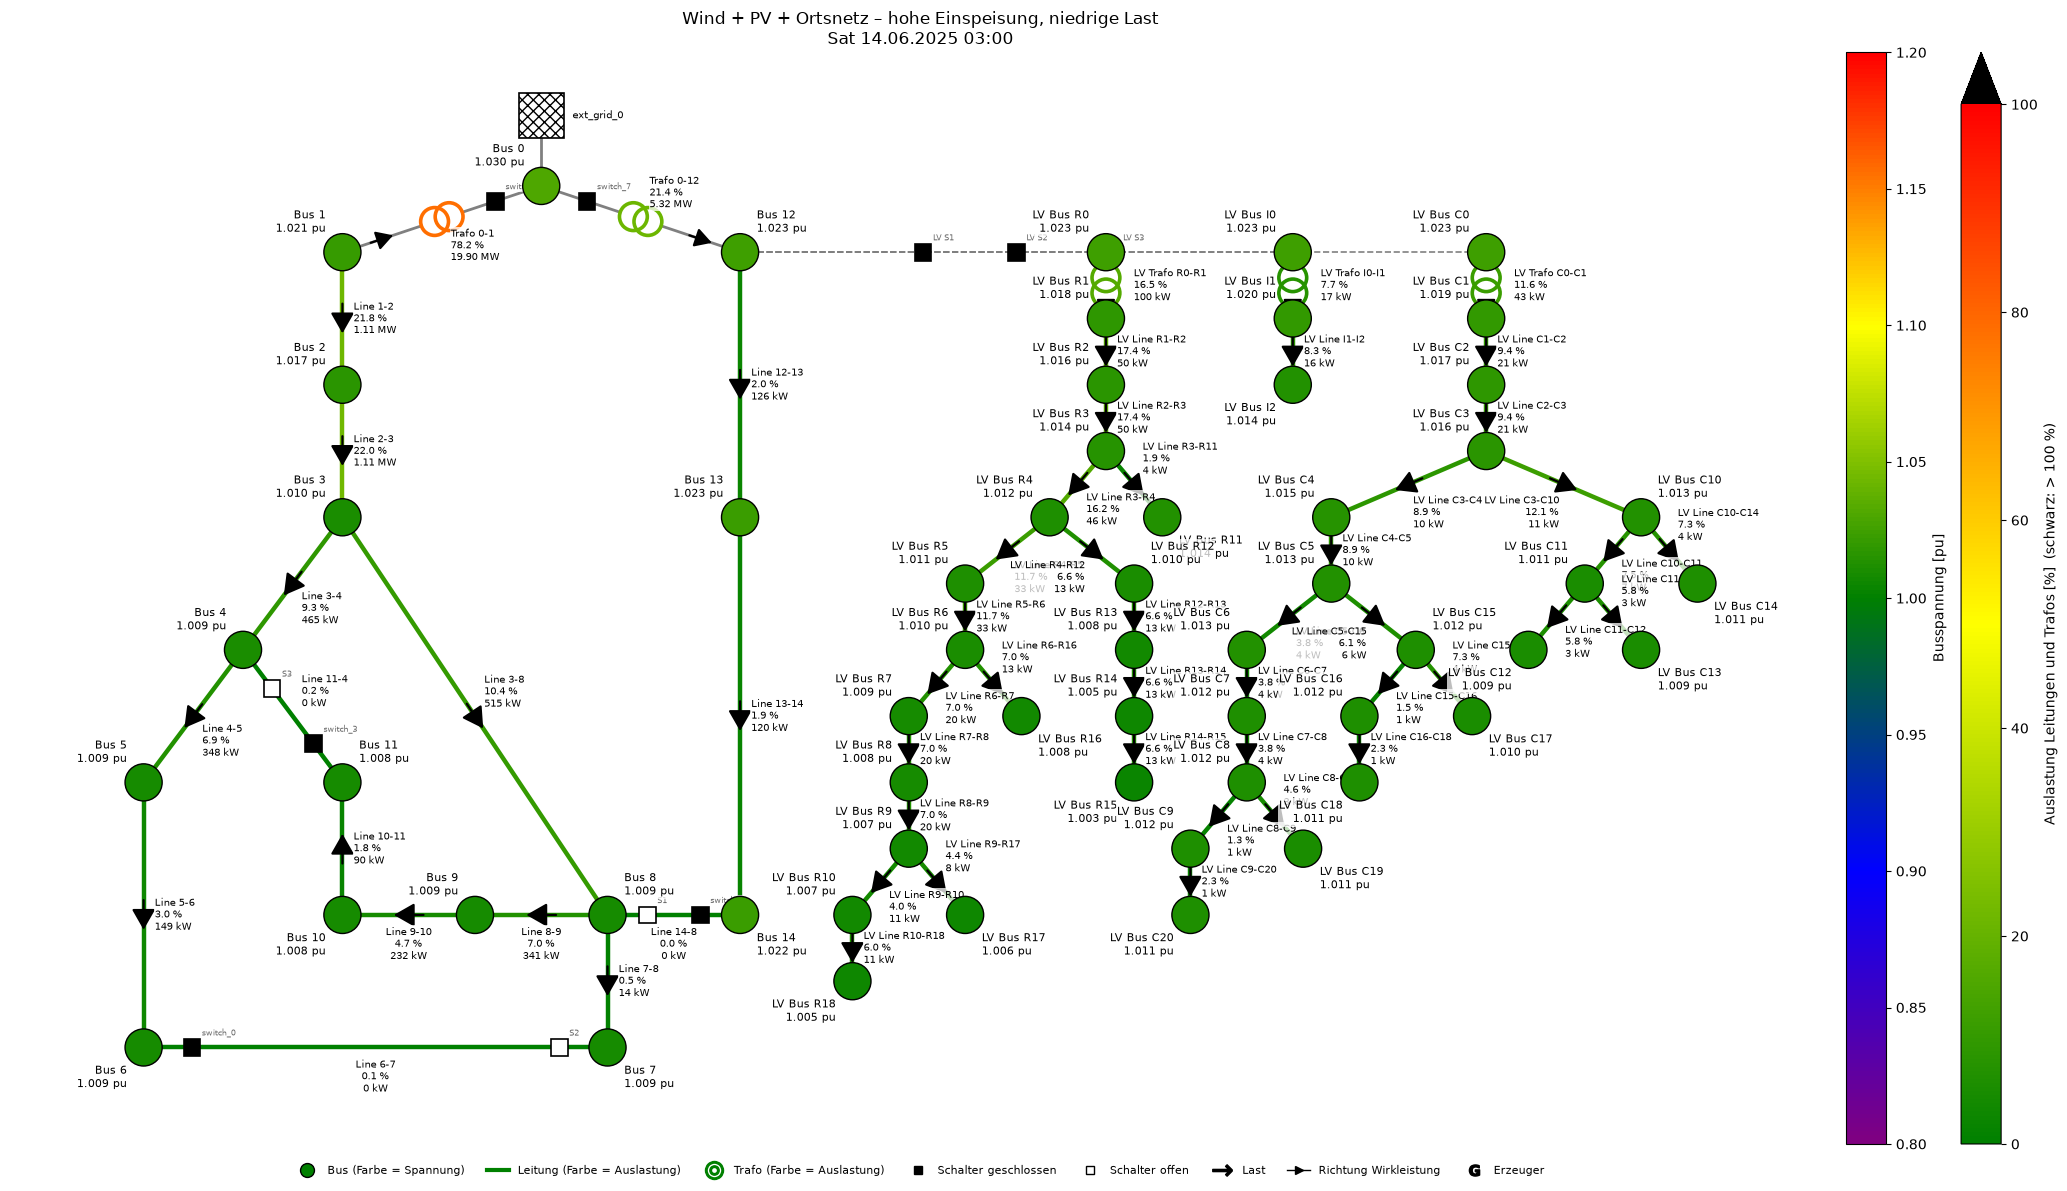

In [12]:
for sit in ("Höchstlast", "hohe Einspeisung, niedrige Last"):
    h = situationen(szen["Wind + PV + Ortsnetz"]["000"])[sit]
    szen["Wind + PV + Ortsnetz"]["000"].createDiagram(Diagram.NETWORK, time=[h], elements=False,
                                                     title=f"Wind + PV + Ortsnetz – {sit}")

**Befund hohe und niedrige Situationen (S1–S3 offen):**

- **Höchstlast** (12.01., 18:00, 37,4 MW Last): Ohne Erzeuger liegt die niedrigste Spannung bei 0,950 pu (Bus 10/11, Planungsband gerade eingehalten). PV und Ortsnetz speisen um diese Zeit nichts ein und ändern nichts. Der Windpark liefert in dieser Stunde 3,3 MW und entlastet Trafo 0-1 von 82,7 auf 70,3 %, die Spannung ändert sich kaum. Die Höchstlast bestimmt in allen Szenarien die niedrigste Spannung.
- **Hohe Einspeisung, niedrige Last:** Beim Windpark ist das eine Nacht im Juni (14.06., 3 Uhr: 26 MW Wind, 11,4 MW Last). Es fließen 14,6 MW ins 110-kV-Netz zurück, Trafo 0-1 ist mit 78 % fast so hoch ausgelastet wie bei Höchstlast. Die Spannung steigt an allen MS-Bussen auf über 1,008 pu, höchstens 1,024 pu. Bei PV und Ortsnetz liegt dieser Zeitpunkt mittags (19.05., 13 Uhr): Die PV-Anlage senkt den Bezug, die Spannungen bleiben zwischen 0,96 und 1,03 pu.
- **Höchste Einspeisung:** Voller Wind (30 MW, 06.01., 6 Uhr) bei mittlerer Last führt zu 8 MW Rückspeisung. Mit Wind und PV zusammen (08.02., 12 Uhr, 36 MW) gleichen sich Einspeisung und Last fast aus (3,1 bis 3,4 MW Rückspeisung), die Trafos sind dann nur halb ausgelastet.
- **Schwachlast ohne Einspeisung** (Nacht im September, 10,3 MW): Die höchsten Spannungen im Netz (1,024 pu an Bus 1, 1,024 pu im Ortsnetz) entstehen hier durch die feste Slack-Spannung von 1,03 pu und den geringen Spannungsfall, nicht durch die Erzeuger.
- **Alle Busse:** Die Tabelle zeigt, dass in keiner Situation ein MS- oder NS-Bus das Planungsband 0,95 … 1,05 pu verlässt. Die Spannungsspanne über alle Situationen ist ohne und mit Erzeugern fast gleich: Die Erzeuger hängen an den Trafo-Sammelschienen und verschieben die Spannung in den Abgängen nur wenig. Größer ist der Unterschied zwischen Höchst- und Schwachlast (bis 6 Prozentpunkte an Bus 11).

## 5 Blindleistungsverhalten

Bisher speisen Windpark und PV-Anlage mit cos φ = 1. Nach der TAR Mittelspannung müssen Erzeugungsanlagen am MS-Netz Blindleistung nach Vorgabe des Netzbetreibers bereitstellen können, z. B. als fester Verschiebungsfaktor oder spannungsabhängig, im Bereich von etwa cos φ = 0,95 untererregt bis 0,95 übererregt [31]. Verglichen wird:

- **cos φ = 1:** reine Wirkleistung (bisher)
- **cos φ = 0,95 untererregt:** Die Anlagen nehmen Blindleistung auf (q = −0,33 · p). Das senkt die Spannung am Anschlusspunkt, erhöht aber den Strom.

Gerechnet für Wind, PV und Wind + PV + Ortsnetz im Normalschaltzustand. Die Spannungsänderung lässt sich mit ΔU ≈ (R · P + X · Q) / U abschätzen [19]: Ein negativer Q-Beitrag kompensiert einen Teil des Spannungsanstiegs durch P, und zwar umso stärker, je größer X/R ist.

In [13]:
def mit_cosphi(s, name, cosphi):
    q = s.copy(name, overwrite=True)
    for g in ("Windpark", "PV-Freifläche"):
        if g in set(q.net.sgen["name"]):
            q.changeParameter(g, "cos_phi", cosphi)
    q.save(results=False)
    return q

blind = {}
for name, s in (("Wind", szen["Wind"]["000"]), ("PV", szen["PV"]["000"]), ("Wind + PV + Ortsnetz", szen["Wind + PV + Ortsnetz"]["000"])):
    q = mit_cosphi(s, f"w4_t4b_q_{name.replace(' + ', '_').replace(' ', '_').lower()}", -0.95)
    q.runSimulation(controllers=aw.lv_regler(q.net))
    blind[(name, "cos φ = 1")] = s
    blind[(name, "cos φ = 0,95 untererregt")] = q

def q_kennwerte(s):
    r = s.results
    w, _ = bw.kennwerte({"x": s})
    w = w.iloc[0]
    erz = [c for c in ("Windpark", "PV-Freifläche") if c in r.sgen_q_mvar]
    return {"U max MS [pu]": w["U max MS [pu]"], "U min MS [pu]": w["U min MS [pu]"], "U max NS [pu]": w["U max NS [pu]"],
            "Leitung max MS [%]": w["Leitung max MS [%]"], "Trafo max HS/MS [%]": w["Trafo max HS/MS [%]"],
            "Verluste [MWh]": w["Verluste [MWh]"],
            "Q der Anlagen min [Mvar]": float(r.sgen_q_mvar[erz].sum(axis=1).min()) if erz else 0.0,
            "Q-Bezug 110 kV max [Mvar]": float(r.ext_grid_q_mvar.squeeze().max()),
            "Q-Bezug 110 kV Mittel [Mvar]": float(r.ext_grid_q_mvar.squeeze().mean()),
            "Stufenschritte rONT gesamt": int(rg.schaltvorgaenge(s).filter(like="Stufen").sum())}

q_tab = pd.DataFrame({k: q_kennwerte(s) for k, s in blind.items()})
plots.table(q_tab, decimals=3)

Simulation 'w4_t4b_q_wind': unverändert seit dem Lauf vom 2026-11-08T23:26:09 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_q_pv': unverändert seit dem Lauf vom 2026-11-08T23:27:15 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).
Simulation 'w4_t4b_q_wind_pv_ortsnetz': unverändert seit dem Lauf vom 2026-11-08T23:28:26 – gespeicherte Ergebnisse geladen (2016 von 2016 Lastflüssen konvergiert).


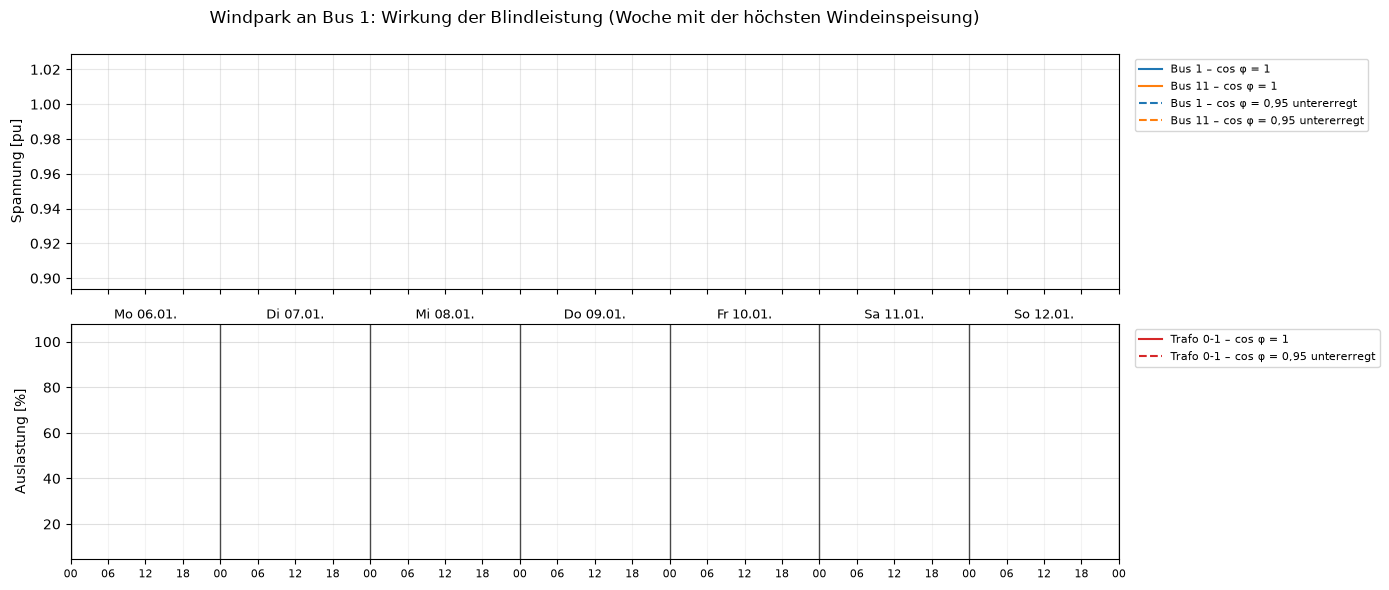

In [14]:
s1, s2 = blind[("Wind", "cos φ = 1")], blind[("Wind", "cos φ = 0,95 untererregt")]
h = s1.results.sgen_p_mw["Windpark"].idxmax()
idx = s1.results.info.index[s1.results.info["month"] == s1.results.info.at[h, "month"]]
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
x = np.arange(len(idx))
for s, ls, lab in ((s1, "-", "cos φ = 1"), (s2, "--", "cos φ = 0,95 untererregt")):
    axes[0].plot(x, s.results.vm_pu.loc[idx, "Bus 1"], ls, color="tab:blue", label=f"Bus 1 – {lab}")
    axes[0].plot(x, s.results.vm_pu.loc[idx, "Bus 11"], ls, color="tab:orange", label=f"Bus 11 – {lab}")
    axes[1].plot(x, s.results.trafo_loading.loc[idx, "Trafo 0-1"], ls, color="tab:red", label=f"Trafo 0-1 – {lab}")
axes[0].set_ylabel("Spannung [pu]")
axes[1].set_ylabel("Auslastung [%]")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
axes[0].set_title("Windpark an Bus 1: Wirkung der Blindleistung (Woche mit der höchsten Windeinspeisung)", pad=22)
plots.week_axis(axes[1], idx)
plt.tight_layout()
plt.show()

**Befund Blindleistung:**

- **PV-Anlage:** Mit cos φ = 0,95 untererregt nimmt sie bis 2,7 Mvar auf. Spannungen und Auslastungen bleiben praktisch gleich, die Verluste steigen um 0,5 MWh. An Bus 12 gibt es kein Spannungsproblem, das die Blindleistung lösen müsste.
- **Windpark:** Mit cos φ = 0,95 untererregt nimmt er bis 9,9 Mvar auf. Das senkt die Spannung in Abgang 1 deutlich: Bei Höchstlast und vollem Wind (06.01., 18:00) fällt Bus 11 auf **0,900 pu**, genau auf die Arbeitsgrenze. In 291 Stunden liegt ein MS-Bus unter 0,95 pu (mit cos φ = 1: 0). Trafo 0-1 muss Wirk- und Blindleistung zugleich übertragen und wird in 11 Stunden überlastet (bis 104 %). Die Verluste steigen um 8 MWh, der Blindleistungsbezug aus dem 110-kV-Netz verdoppelt sich fast (Höchstwert 11,8 → 21,7 Mvar).
- **Erklärung:** Untererregter Betrieb ist dafür gedacht, die Spannungsanhebung durch Einspeisung zu begrenzen. Im CIGRE-Netz liegt die MS-Spannung aber auch bei voller Einspeisung höchstens bei 1,025 pu. Der Windpark hängt direkt an der Trafo-Sammelschiene, deshalb wirkt seine Blindleistung über die Reaktanz von Trafo 0-1 auf den ganzen Abgang 1, auch zur Abendspitze, wenn die Spannung ohnehin niedrig ist.
- **Folgerung:** Für dieses Netz ist cos φ = 1 die bessere Vorgabe. Sinnvoll wäre höchstens eine spannungsabhängige Kennlinie Q(U), die erst bei hoher Spannung Blindleistung aufnimmt, wie sie die TAR Mittelspannung als Verfahren vorsieht [31].

## 6 Ergebnis: Anschlussort, Dimensionierung, Blindleistung und gleichzeitiger Betrieb

**Ergebnis Teil 4:**

- **Anschlussort:** Windpark (30 MW) und PV-Freiflächenanlage (10 MWp) sind nur an den Sammelschienen der 110/20-kV-Trafos anschließbar (Teil 4a). Dort ändern sie die Spannungen in den Abgängen kaum (höchstens +0,2 Prozentpunkte), sondern vor allem die Trafoauslastung und den Austausch mit dem 110-kV-Netz. Die PV-Haushalte speisen dagegen mitten im Ortsnetz ein und heben dort die Spannung bis an das Planungsband.
- **Dimensionierung:** Der Windpark ist so groß, dass er in 233 Stunden mehr erzeugt, als das ganze Netz verbraucht (bis 16,1 MW Rückspeisung). Die PV-Anlage bleibt immer unter der Last. Im Ortsnetz ist die Variante „heute“ mit dem rONT beherrschbar, die Variante „Zukunft“ nicht (Trafo bis 293 %, Spannung bis 1,20 pu).
- **Blindleistung:** Untererregter Betrieb mit cos φ = 0,95 schadet in diesem Netz: Beim Windpark sinkt die Spannung in Abgang 1 bis auf die Arbeitsgrenze 0,90 pu, Trafo 0-1 wird überlastet. cos φ = 1 bleibt die Vorgabe; sinnvoll wäre höchstens Q(U).
- **Gleichzeitiger Betrieb:** Die Wirkungen der Szenarien addieren sich fast genau, weil sie an verschiedenen Stellen einspeisen (Bus 1, Bus 12, Wohngebiet). Zusammen senken sie die Verluste um 12,6 MWh (−8 %) bei offenem S1.
- **Schalterstellungen:** Mit Windpark sollte S1 offen bleiben: Geschlossen steigen die MS-Leitungsauslastung auf bis 99,6 % und die Verluste um rund 55 MWh. S2 und S3 ändern wie bisher fast nichts.
- **Weiter verwendet** wird das Netz „Wind + PV + Ortsnetz (heute)“ (`w4_t5_…`); Teil 5 untersucht darin die Lastflussumkehr.

### Quellen

Nummern wie im zentralen Quellenverzeichnis (`Task4-Datengrundlage.ipynb`, Abschnitt 3).

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[2] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Repräsentative Profile BDEW H25, G25, L25, P25, S25 – Veröffentlichung“, Datensatz (CSV), Berlin, 2025.

[4] P. Zippenfenig, „Open-Meteo.com Weather API“, Zenodo, 2023, doi: 10.5281/ZENODO.7970649.

[6] Open-Meteo, „Historical Weather API – Documentation“. Online: https://open-meteo.com/en/docs/historical-weather-api (Abruf: 14.10.2026).

[11] Trina Solar, „Vertex S+ – Bifaziales Doppelglas N-Typ i-TOPCon Modul, TSM-NEG9RC.27“, Datenblatt, Version TSM_DE_2024_B, 2024. Online: https://www-cdn.trinasolar.com/wwwstorage/sites/8/250227_Datasheet_VertexS_NEG9RC.27_DE_2024_B_web.pdf

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[17] pandapower, „Datastructure and Elements“, Dokumentation der Elemente und Ergebnistabellen (res_bus, res_line, res_trafo, res_ext_grid, res_storage). Online: https://pandapower.readthedocs.io/en/latest/elements.html

[19] A. J. Schwab, *Elektroenergiesysteme: Erzeugung, Transport, Übertragung und Verteilung elektrischer Energie*, 3. Aufl. Berlin, Heidelberg: Springer, 2012, doi: 10.1007/978-3-642-21958-0.

[23] KfW Research, „Fast 13 Millionen Haushalte nutzen Energiewendetechnologien“, Pressemitteilung, 12.09.2024 (KfW-Energiewendebarometer). Online: https://www.kfw.de/%C3%9Cber-die-KfW/Newsroom/Aktuelles/Pressemitteilungen-Details_821696.html

[24] Fraunhofer ISE, „Photovoltaics Report“, Freiburg. Online: https://www.ise.fraunhofer.de/content/dam/ise/de/documents/publications/studies/Photovoltaics-Report.pdf

[30] VDE-AR-N 4105, „Erzeugungsanlagen am Niederspannungsnetz – Technische Mindestanforderungen für Anschluss und Parallelbetrieb von Erzeugungsanlagen am Niederspannungsnetz“, Berlin: VDE Verlag, 2018.

[31] VDE-AR-N 4110, „Technische Regeln für den Anschluss von Kundenanlagen an das Mittelspannungsnetz und deren Betrieb (TAR Mittelspannung)“, Berlin: VDE Verlag, 2023.

[32] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Stromverbrauch vergleichen und Sparpotenzial nutzen“, Presseinformation, 21.04.2016. Online: https://www.bdew.de/presse/presseinformationen/stromverbrauch-vergleichen-und-sparpotenzial-nutzen/

[33] RWTH Aachen, Institut für Stromrichtertechnik und Elektrische Antriebe (ISEA), „Battery Charts“, Auswertung des Marktstammdatenregisters, Methodik. Online: https://battery-charts.de/de/battery-charts-de/; Quartalswerte Q1 2026 nach pv magazine, 08.05.2026. Online: https://www.pv-magazine.de/2026/05/08/starkes-wachstum-im-grossspeichermarkt-fuehrt-zu-batterie-rekordzubau-von-ueber-2-gigawattstunden-im-1-quartal-2026/

[34] Meissner et al. (HTW Berlin), „Feldmessdaten von 110 PV-Speichersystemen“, 2024. Online: https://solar.htw-berlin.de/wp-content/uploads/MEISSNER-2024-Feldmessdaten-von-110-PV-Speichersystemen.pdf

[35] HTW Berlin, „Stromspeicher-Inspektion 2025“, Berlin, 2025. Online: https://solar.htw-berlin.de/wp-content/uploads/HTW-Stromspeicher-Inspektion-2025.pdf; Zusammenfassung: Solarserver, 07.02.2025. Online: https://www.solarserver.de/2025/02/07/stromspeicher-inspektion-2025-neue-wirkungsgradrekorde-von-kostal-und-sax-power/

[37] RWTH Aachen und LUBW, „Speichermonitoring BW 2.0“, Karlsruhe. Online: https://pudi.lubw.de/detailseite/-/publication/10501-Speichermonitoring_BW_2.0.pdf
